--- Step 1: Loading iris.txt Dataset ---
Dataset Shape: (150, 5)

First 5 rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

--- Step 2: Generating Exploratory Pairplot ---


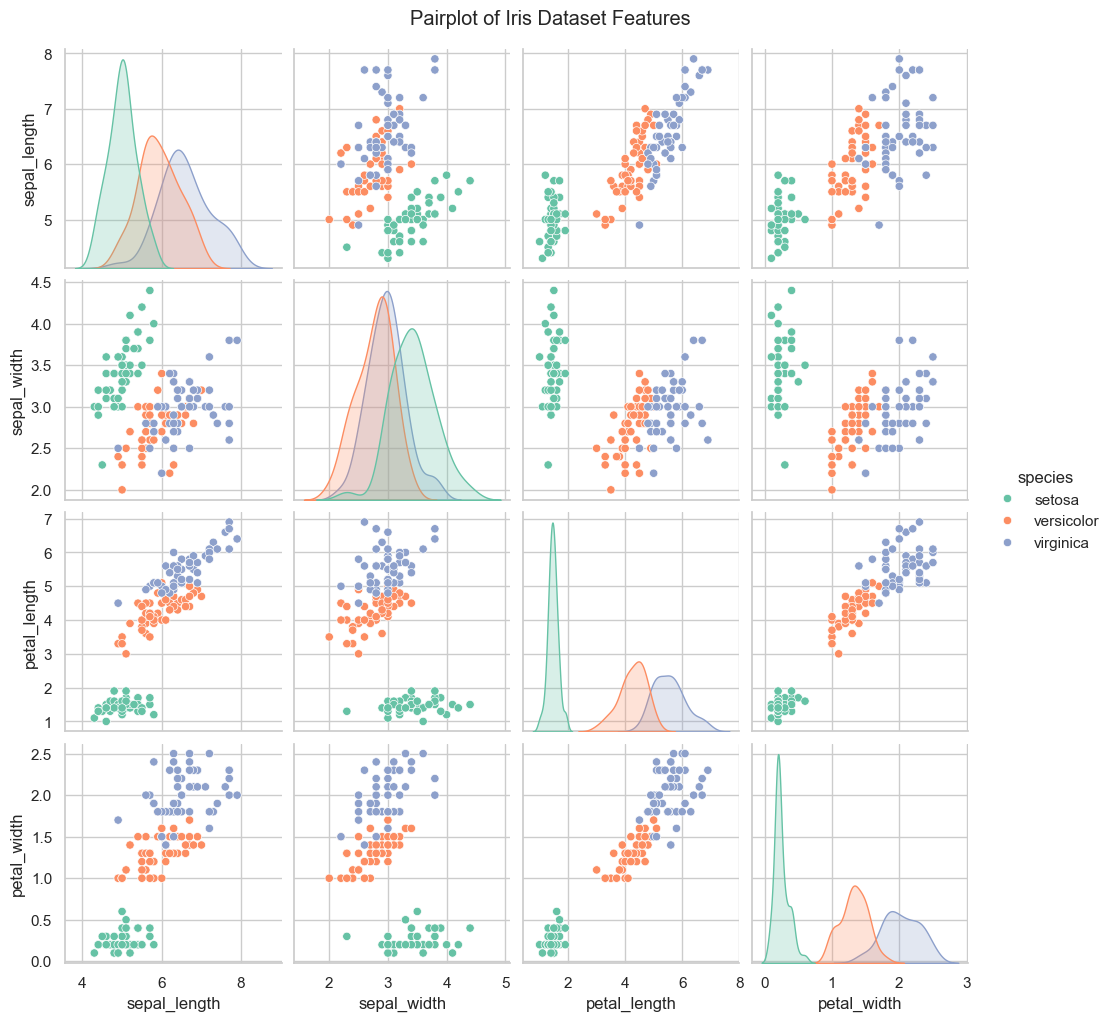


--- Step 3: Train/Test Split (80/20) & Normalization ---
Training Samples: 120, Test Samples: 30

--- Step 4: Model Training and Benchmarking ---

==================== Logistic Regression ====================
Accuracy : 0.9333
Precision: 0.9333
Recall   : 0.9333
F1-Score : 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


==================== Decision Tree ====================
Accuracy : 0.9333
Precision: 0.9333
Recall   : 0.9333
F1-Score : 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        

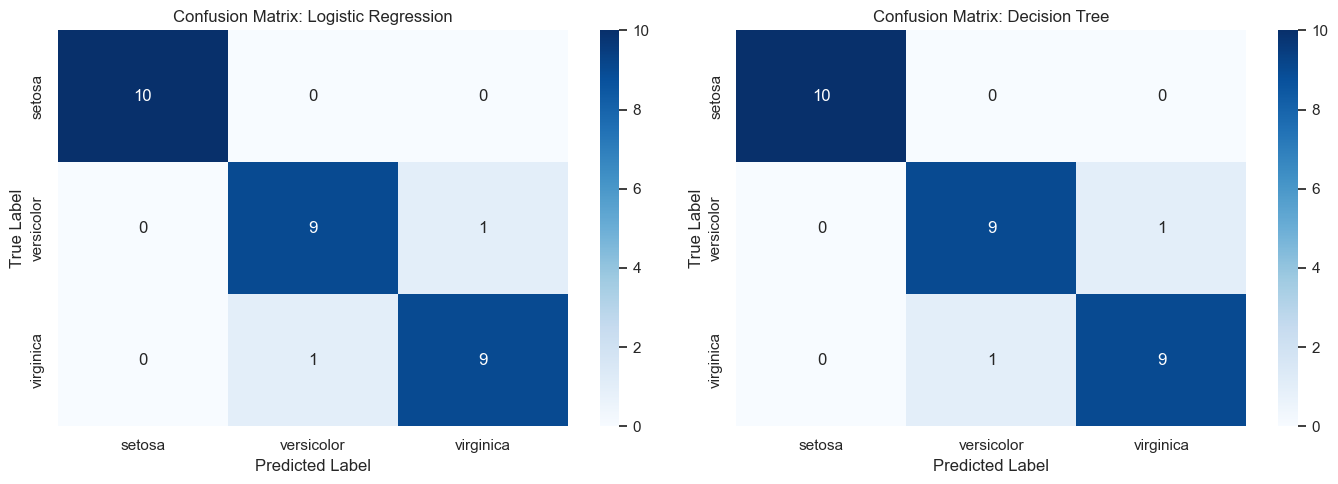


--- Step 6: Visualizing Decision Boundaries ---


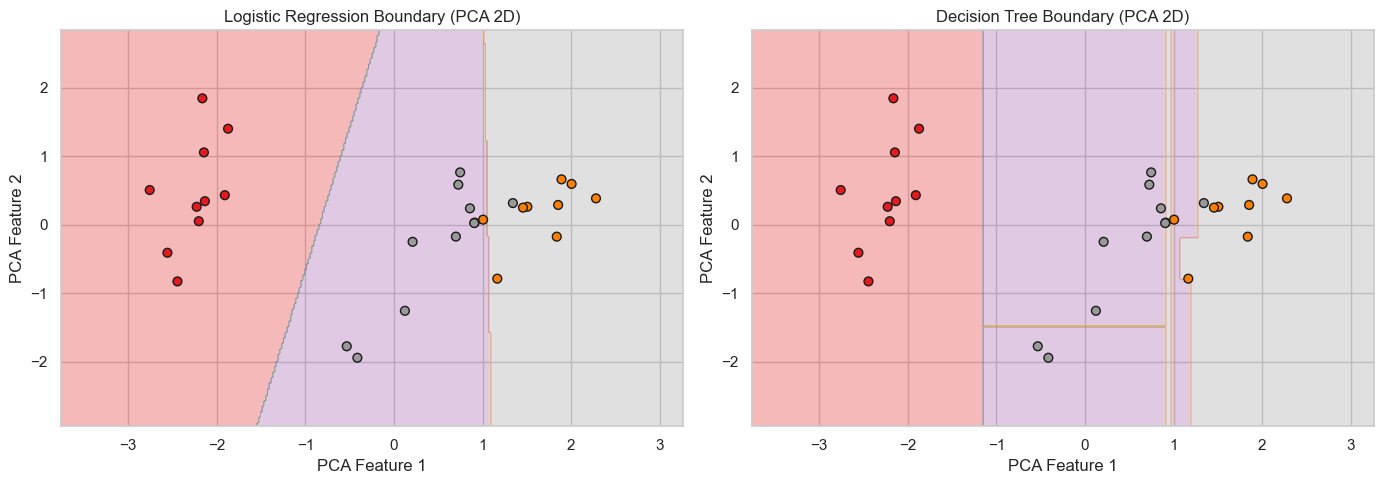

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

print("--- Step 1: Loading iris.txt Dataset ---")
df = pd.read_csv("D:\iris.txt")

print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 rows:")
print(df.head())

X = df.drop(columns=['species'])
y = df['species']
target_names = y.unique() # ['setosa', 'versicolor', 'virginica']

print("\n--- Step 2: Generating Exploratory Pairplot ---")
sns.pairplot(df, hue='species', palette='Set2')
plt.suptitle("Pairplot of Iris Dataset Features", y=1.02)
plt.show()

print("\n--- Step 3: Train/Test Split (80/20) & Normalization ---")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Samples: {X_train_scaled.shape[0]}, Test Samples: {X_test_scaled.shape[0]}")

print("\n--- Step 4: Model Training and Benchmarking ---")

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    print(f"\n==================== {name} ====================")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=target_names)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=target_names, yticklabels=target_names, ax=ax)
    ax.set_title(f'Confusion Matrix: {name}')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()
s
print("\n--- Step 6: Visualizing Decision Boundaries ---")

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

y_train_encoded = pd.factorize(y_train)[0]
y_test_encoded = pd.factorize(y_test)[0]

def plot_decision_boundary(model, X, y, title, ax):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    # If predictions are strings, map them back to numeric codes for plotting
    if Z.dtype.kind in 'USO':
        Z = pd.factorize(Z)[0]
    Z = Z.reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1)
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Set1, edgecolor='k', s=40)
    ax.set_title(title)
    ax.set_xlabel('PCA Feature 1')
    ax.set_ylabel('PCA Feature 2')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model_class) in zip(axes, [
    ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42)),
    ("Decision Tree", DecisionTreeClassifier(random_state=42))
]):
    clf_2d = model_class
    clf_2d.fit(X_train_pca, y_train)
    plot_decision_boundary(clf_2d, X_test_pca, y_test_encoded, f"{name} Boundary (PCA 2D)", ax)

plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def run_housing_project():
    # 1. Load the dataset
    print("Loading dataset...")
    df = pd.read_csv(r"C:\Users\H.P\Desktop\housing.txt")
    
    print(f"Dataset Shape: {df.shape}")
    print("\nFirst 5 rows of the dataset:")
    print(df.head())

    # 2. Separate features (X) and target variable (y)
    X = df.drop("median_house_value", axis=1)
    y = df["median_house_value"]

    # 3. Identify numeric and categorical features
    numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = X.select_dtypes(include=['object']).columns.tolist()

    print(f"\nNumeric features: {numeric_features}")
    print(f"Categorical features: {categorical_features}")

    # 4. Create preprocessing pipelines
    # Fill missing numeric values with the median
    numeric_transformer = SimpleImputer(strategy='median')

    # Handle categorical variables with OneHotEncoding
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ])

    # 5. Combine preprocessor and model into a single pipeline
    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ])

    # 6. Split data into training and testing sets (80% train, 20% test)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 7. Train the model
    print("\nTraining the Random Forest model...")
    model.fit(X_train, y_train)

    # 8. Predict and Evaluate
    print("Evaluating model performance...")
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print("\n--- Model Performance Metrics ---")
    print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
    print(f"R-squared ($R^2$ Score): {r2:.4f}")

if __name__ == "__main__":
    run_housing_project()

Loading dataset...
Dataset Shape: (20640, 10)

First 5 rows of the dataset:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  

Dataset Shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

C:\Users\H.P\AppData\Local\Temp\ipykernel_16504\499814149.py:20: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)



--- Model Evaluation Results ---
Accuracy Score: 0.7857
ROC-AUC Score: 0.8246

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409



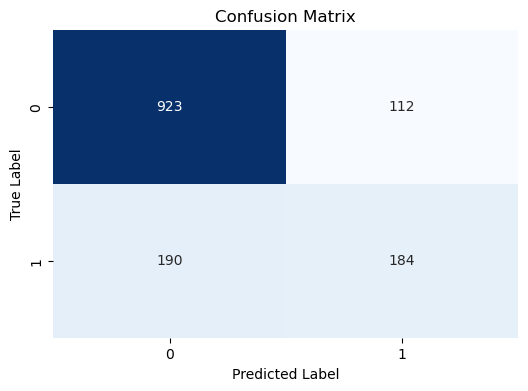

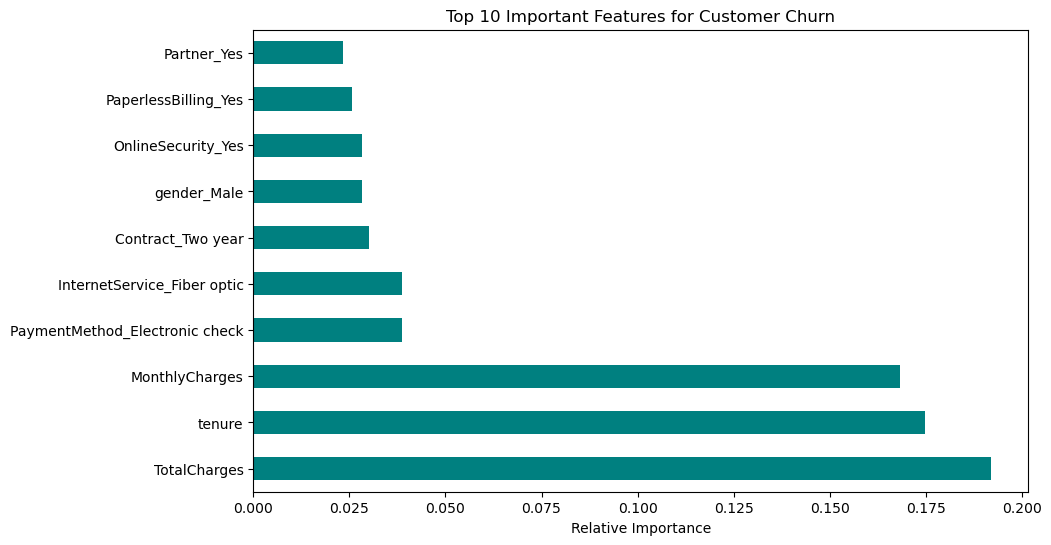

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\H.P\Desktop\Telco-Customer-Churn.txt")

print(f"Dataset Shape: {df.shape}")
print(df.head())

if 'customerID' in df.columns:
    df = df.drop('customerID', axis=1)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

df['Churn'] = df['Churn'].apply(lambda x: 1 if x.strip() == 'Yes' else 0)

categorical_cols = df.select_dtypes(include=['object']).columns

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print(f"Dataset shape after encoding: {df.shape}")

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("\nTraining the Random Forest Classifier...")
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\n--- Model Evaluation Results ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

feature_importances = pd.Series(model.feature_importances_, index=X.columns)
plt.figure(figsize=(10, 6))
feature_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Important Features for Customer Churn')
plt.xlabel('Relative Importance')
plt.show()

In [1]:
import pandas as pd
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

print("Loading dataset...")
df = pd.read_csv(r"C:\Users\H.P\Desktop\sentiment_reviews.csv")
print(f"Dataset shape: {df.shape}")
print(df.head(), "\n")

STOP_WORDS = {
    'i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", 
    "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 
    'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', 
    "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 
    'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 
    'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 
    'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 
    'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 
    'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 
    'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 
    'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 
    'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 
    'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', 'too', 
    'very', 's', 't', 'can', 'will', 'just', 'don', "don't", 'should', "should've", 
    'now', 'd', 'll', 'm', 'o', 'r', 'v', 'y', 'ain', 'aren', "aren't", 'couldn', 
    "couldn't", 'didn', "didn't", 'doesn', "doesn't", 'hadn', "hadn't", 'hasn', 
    "hasn't", 'haven', "haven't", 'isn', "isn't", 'ma', 'mightn', "mightn't", 
    'mustn', "mustn't", 'needn', "needn't", 'shan', "shan't", 'shouldn', 
    "shouldn't", 'wasn', "wasn't", 'weren', "weren't", 'won', "won't", 'wouldn', "wouldn't"
}

def preprocess_text(text):
    text = re.sub(r'<.*?>', '', str(text))
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = text.split()
    tokens = [word for word in tokens if word not in STOP_WORDS]
    return ' '.join(tokens)

print("Preprocessing review texts...")
df['clean_text'] = df['review_text'].apply(preprocess_text)

print("Extracting TF-IDF features...")
vectorizer = TfidfVectorizer(max_features=5000)

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['sentiment'], test_size=0.2, random_state=42
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("\n--- Training Multinomial Naive Bayes ---")
nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train)
nb_preds = nb_model.predict(X_test_vec)
print("Accuracy:", accuracy_score(y_test, nb_preds))
print(classification_report(y_test, nb_preds, zero_division=0))

print("\n--- Training Logistic Regression ---")
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)
lr_preds = lr_model.predict(X_test_vec)
print("Accuracy:", accuracy_score(y_test, lr_preds))
print(classification_report(y_test, lr_preds, zero_division=0))

def predict_sentiment(phrases, model=lr_model, vec=vectorizer):
    """
    Tests live custom user input phrases and predicts their sentiment.
    """
    if isinstance(phrases, str):
        phrases = [phrases]
        
    cleaned_phrases = [preprocess_text(p) for p in phrases]
    phrases_vec = vec.transform(cleaned_phrases)
    predictions = model.predict(phrases_vec)
    
    results = []
    for phrase, pred in zip(phrases, predictions):
        results.append({"Phrase": phrase, "Predicted Sentiment": pred})
        
    return pd.DataFrame(results)

print("\n--- Testing Live Custom Input Phrases ---")
test_phrases = [
    "This is an amazing item, I am completely blown away!",
    "Awful quality, broke on the very first day.",
    "It is okay, nothing particularly great or bad."
]

print(predict_sentiment(test_phrases))

Loading dataset...
Dataset shape: (10, 3)
   review_id                                        review_text sentiment
0          1  The product quality is exceptional, exceeded a...  positive
1          2  Terrible customer service and the item arrived...  negative
2          3  Average performance, decent for the price poin...   neutral
3          4  Absolutely love this! Easy to setup, robust, a...  positive
4          5  Stopped working after two days. Extremely disa...  negative 

Preprocessing review texts...
Extracting TF-IDF features...

--- Training Multinomial Naive Bayes ---
Accuracy: 0.0
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       2.0
    positive       0.00      0.00      0.00       0.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0


--- Training Logistic Regression ---
Accuracy: 0.0
              pre